In [21]:
import torch
from torch import nn, optim
import matplotlib.pyplot as plt
from itertools import chain

In [22]:
torch.manual_seed(123)

I = (-4, 4)
X = torch.linspace(*I, 100)
Y = torch.linspace(*I, 100)

input = torch.cartesian_prod(X, Y)
output = input.sum(dim=1).cos().reshape(-1, 1)

In [23]:
class NeuralNetwork(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.stack = nn.Sequential(
            nn.Linear(2, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, 1)
        )

    def forward(self, x):
        return self.stack(x)

model1 = NeuralNetwork(hidden_size=10)
model2 = NeuralNetwork(hidden_size=10)
models = (model1, model2)

def my_muon(W, lr):
    lr_scale = max(1, W.shape[0] / W.shape[1]) ** 0.5
    return optim.Muon(
        [W], lr=lr / lr_scale,
        momentum=0.0, nesterov=False, weight_decay=0.0,
        ns_coefficients=(1.5, -0.5, 0.0), ns_steps=10,
        adjust_lr_fn="original",
    )

optimizer1 = [optim.SGD(model1.parameters(), lr=0.035)]
optimizer2 = [
    my_muon(model2.stack[0].weight, lr=0.001),
    my_muon(model2.stack[2].weight, lr=0.001),
    optim.SGD(chain([model2.stack[0].bias, model2.stack[2].bias], model2.stack[4].parameters()), lr=0.02)
]
optimizers = (optimizer1, optimizer2)

loss = nn.MSELoss()

In [24]:
epoch = 2000

losses1 = []
losses2 = []
losses = (losses1, losses2)

for _ in range(epoch):
    for mod, optim, ls in zip(models, optimizers, losses):
        for opt in optim:
            opt.zero_grad()
        pred = mod(input)
        loss_value = loss(pred, output)
        ls.append(loss_value.item())
        loss_value.backward()
        for opt in optim:
            opt.step()

SGD final loss: 0.019532
Spectral GD + SGD final loss: 0.019019


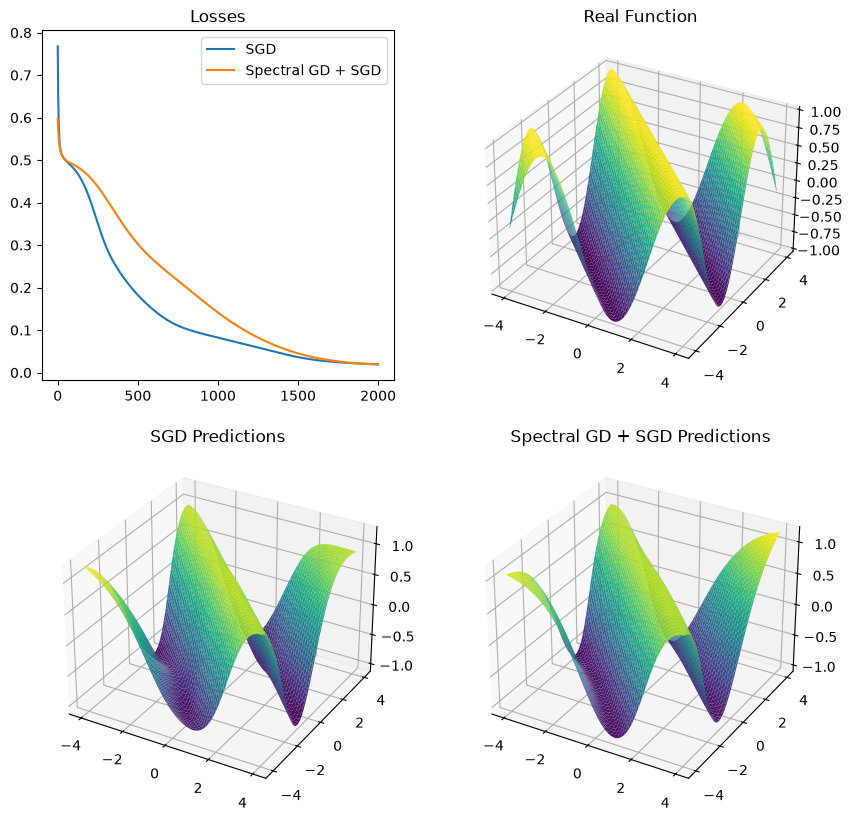

In [25]:
with torch.no_grad():
    pred1 = model1(input)
    pred2 = model2(input)
    predictions = (pred1, pred2)

fig = plt.figure(figsize=(10, 10))

names = ("SGD", "Spectral GD + SGD")

loss_ax = fig.add_subplot(2, 2, 1)
loss_ax.set_title("Losses")
for name, ls in zip(names, losses):
    loss_ax.plot(ls, label=name)
    print(f"{name} final loss: {ls[-1]:.6f}")
loss_ax.legend()

X_plot, Y_plot = torch.meshgrid(X, Y)

real_ax = fig.add_subplot(2, 2, 2, projection='3d')
real_ax.plot_surface(X_plot, Y_plot, output.numpy().reshape(100, 100), cmap='viridis')
real_ax.set_title("Real Function")

for i, (name, pred) in enumerate(zip(names, predictions)):
    ax = fig.add_subplot(2, 2, i + 3, projection='3d')
    ax.plot_surface(X_plot, Y_plot, pred.numpy().reshape(100, 100), cmap='viridis')
    ax.set_title(f"{name} Predictions")

plt.show()